# Exploring Data

In [2]:
# %pip install praw
import praw

In [6]:
# %pip install dotenv
from dotenv import load_dotenv
import os

load_dotenv()

REDDIT_CLIENT_ID = os.getenv("REDDIT_CLIENT_ID")
REDDIT_CLIENT_SECRET = os.getenv("REDDIT_CLIENT_SECRET")

In [8]:
reddit = praw.Reddit(
    client_id=REDDIT_CLIENT_ID,
    client_secret=REDDIT_CLIENT_SECRET,
    user_agent="minimal_script/0.1",
)

## Identifying Subreddits of Interest (SOIs)

In [16]:
SORT_OPTIONS = ["relevance", "hot", "top", "new", "comments"]
TIME_FILTERS = ["all", "year", "month", "week", "day", "hour"]

In [62]:
SEARCH_TERM = "resume"
subs = reddit.subreddits.search(SEARCH_TERM, limit=100)

In [63]:
sub_dict = {"subreddit_name": [], "subscribers": [], "created_at": []}
for sub in subs:
    sub_dict["subreddit_name"].append(sub.display_name)
    sub_dict["subscribers"].append(sub.subscribers)
    sub_dict["created_at"].append(sub.created_utc)

In [65]:
import pandas as pd

subs_df = pd.DataFrame(sub_dict)

In [67]:
# subs_df.to_csv("subs_df_snapshot_11_11_2026.csv", index=False)

In [68]:
subs_df.sort_values(by="subscribers", ascending=False)

,subreddit_name,subscribers,created_at
49,funny,67653694,1.201243e+09
20,AskReddit,60115396,1.201233e+09
24,worldnews,47703084,1.201231e+09
77,Showerthoughts,34210417,1.318973e+09
59,news,31611803,1.201244e+09
...,...,...,...
96,optimizedcv,25,1.743981e+09
40,ResumeFeedback,19,1.708301e+09
67,ActualResumeHelp,17,1.782882e+09
53,BestResume,16,1.759677e+09


In [78]:
mentions_resume = subs_df["subreddit_name"].str.contains("resume", case=False)

In [77]:
mentions_resume.value_counts()

subreddit_name
False    53
True     47
Name: count, dtype: int64

<Axes: >

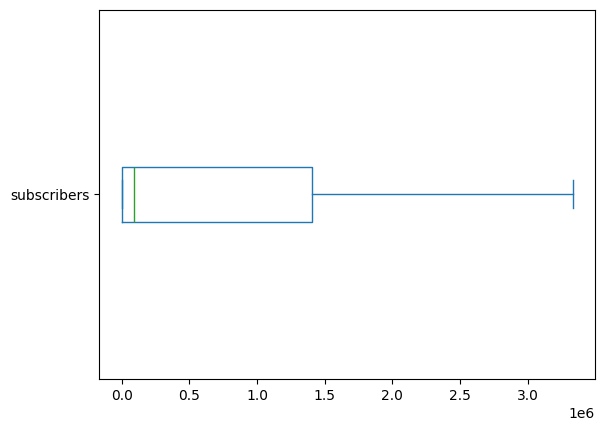

In [74]:
subs_df["subscribers"].plot.box(showfliers=False, vert=False)

In [60]:
subs_df

,subreddit_name,subscribers,created_at
